# 🎵 Notebook 4: Acoustic Music Genre Response Classification

## 1. Scientific Background & Hypothesis
Distinguishing plant responses across musical genres (`classical`, `devotional`, `pop`, `silence`).
All plots will be saved to `plot/04_music_genre_gradient_boosting/`.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

NOTEBOOK_NAME = "04_music_genre_gradient_boosting"
if os.path.basename(os.getcwd()) == "notebook":
    PLOT_DIR = os.path.join("..", "plot", NOTEBOOK_NAME)
    DATA_PATH = "plant_time_series_features.csv"
else:
    PLOT_DIR = os.path.join("plot", NOTEBOOK_NAME)
    DATA_PATH = os.path.join("notebook", "plant_time_series_features.csv") if os.path.exists(os.path.join("notebook", "plant_time_series_features.csv")) else "plant_time_series_features.csv"

os.makedirs(PLOT_DIR, exist_ok=True)
print(f"Plots will be saved to: {os.path.abspath(PLOT_DIR)}")

df = pd.read_csv(DATA_PATH)
genre_map = {
    "normal": "Silence / Normal",
    "music/classical": "Classical Music",
    "music/devotional": "Devotional Music",
    "music/pop": "Pop Music"
}
music_df = df[df["category"].isin(genre_map.keys())].copy()
music_df["genre"] = music_df["category"].map(genre_map)
print(music_df["genre"].value_counts())


Plots will be saved to: C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\plot\04_music_genre_gradient_boosting
genre
Silence / Normal    963
Devotional Music    905
Pop Music           791
Classical Music     297
Name: count, dtype: int64


## 2. Spectral Power Distribution Across Acoustic Genres

C:\Users\asim\AppData\Local\Temp\ipykernel_14080\4293468771.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=music_df, x="genre", y="low_freq_power", ax=ax1, palette="Set3")
C:\Users\asim\AppData\Local\Temp\ipykernel_14080\4293468771.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=music_df, x="genre", y="high_freq_power", ax=ax2, palette="Set3")
C:\Users\asim\AppData\Local\Temp\ipykernel_14080\4293468771.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=music_df, x="genre", y="spectral_entropy", ax=ax3, palette="Set3

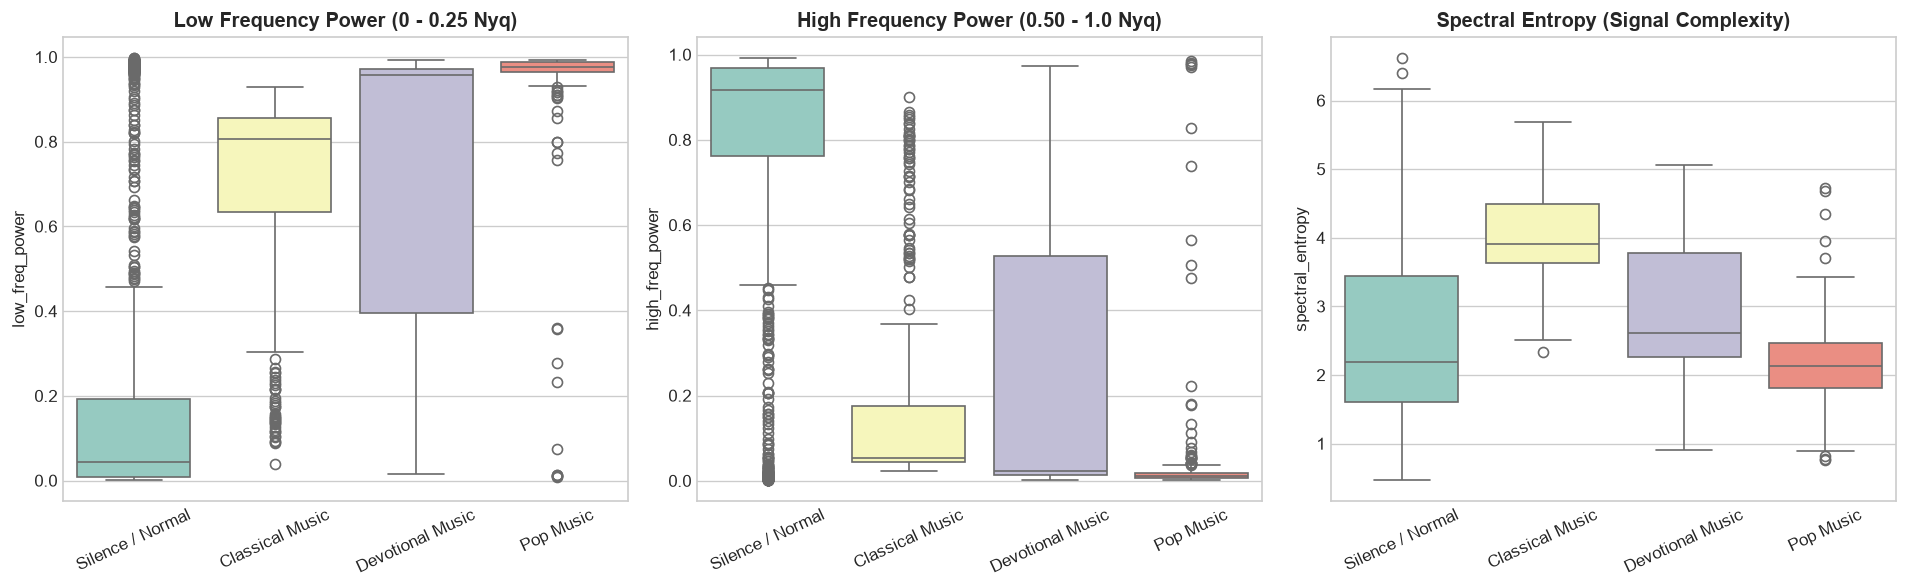

In [2]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=music_df, x="genre", y="low_freq_power", ax=ax1, palette="Set3")
ax1.set_title("Low Frequency Power (0 - 0.25 Nyq)", fontweight='bold')
ax1.set_xlabel("")
ax1.tick_params(axis='x', rotation=25)

sns.boxplot(data=music_df, x="genre", y="high_freq_power", ax=ax2, palette="Set3")
ax2.set_title("High Frequency Power (0.50 - 1.0 Nyq)", fontweight='bold')
ax2.set_xlabel("")
ax2.tick_params(axis='x', rotation=25)

sns.boxplot(data=music_df, x="genre", y="spectral_entropy", ax=ax3, palette="Set3")
ax3.set_title("Spectral Entropy (Signal Complexity)", fontweight='bold')
ax3.set_xlabel("")
ax3.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "1_spectral_power_distributions.png"), dpi=300, bbox_inches='tight')
plt.show()


## 3. Train Gradient Boosting Classifier (GBDT)

In [3]:
feature_cols = [
    "mean", "std", "var", "range", "rms", "mad", 
    "zcr", "skew", "kurt", "peak_count",
    "low_freq_power", "mid_freq_power", "high_freq_power", 
    "spectral_entropy", "dominant_freq"
]

genres = ["Silence / Normal", "Classical Music", "Devotional Music", "Pop Music"]
genre_to_idx = {g: i for i, g in enumerate(genres)}

X_music = music_df[feature_cols].values
y_music = music_df["genre"].map(genre_to_idx).values
groups_music = music_df["session_id"].values

sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
gbdt_model = HistGradientBoostingClassifier(max_iter=120, random_state=42)
oof_preds_gbdt = np.zeros(len(y_music), dtype=int)

for fold, (tr_idx, te_idx) in enumerate(sgkf.split(X_music, y_music, groups_music)):
    gbdt_model.fit(X_music[tr_idx], y_music[tr_idx])
    oof_preds_gbdt[te_idx] = gbdt_model.predict(X_music[te_idx])

print("=== Gradient Boosting Classification Report ===")
print(classification_report(y_music, oof_preds_gbdt, target_names=genres))


=== Gradient Boosting Classification Report ===
                  precision    recall  f1-score   support

Silence / Normal       0.69      0.69      0.69       963
 Classical Music       0.00      0.00      0.00       297
Devotional Music       0.38      0.43      0.41       905
       Pop Music       0.71      0.73      0.72       791

        accuracy                           0.55      2956
       macro avg       0.44      0.46      0.45      2956
    weighted avg       0.53      0.55      0.54      2956



## 4. Multi-Genre Normalized Confusion Matrix

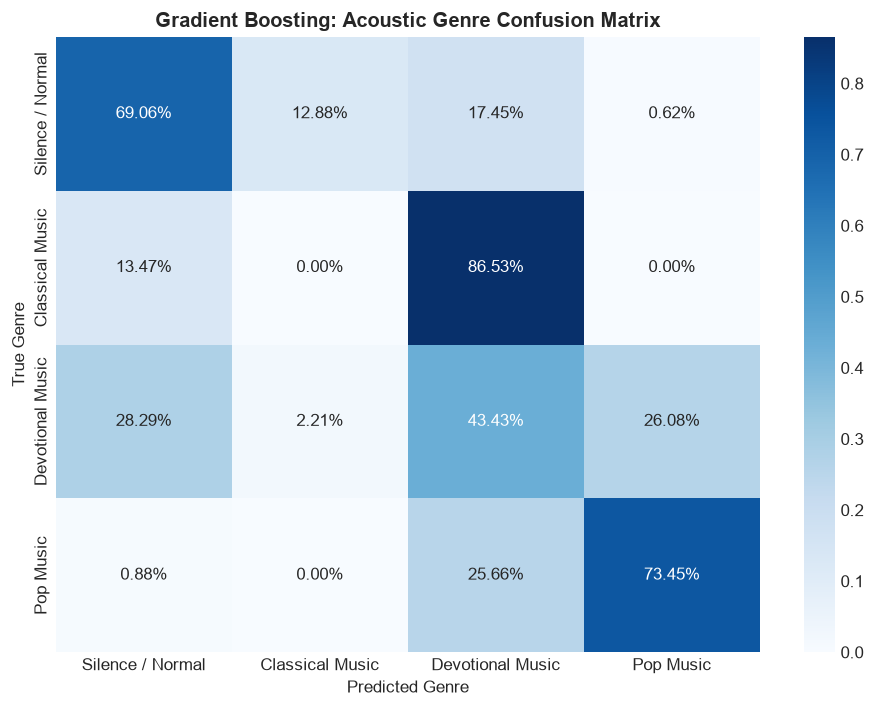

In [4]:
plt.figure(figsize=(8, 6))
cm_genre = confusion_matrix(y_music, oof_preds_gbdt, normalize='true')
sns.heatmap(cm_genre, annot=True, fmt=".2%", cmap="Blues", xticklabels=genres, yticklabels=genres)
plt.title("Gradient Boosting: Acoustic Genre Confusion Matrix", fontweight='bold')
plt.ylabel("True Genre")
plt.xlabel("Predicted Genre")
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "2_genre_confusion_matrix.png"), dpi=300, bbox_inches='tight')
plt.show()


## 5. Feature Importance in Genre Discrimination

C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


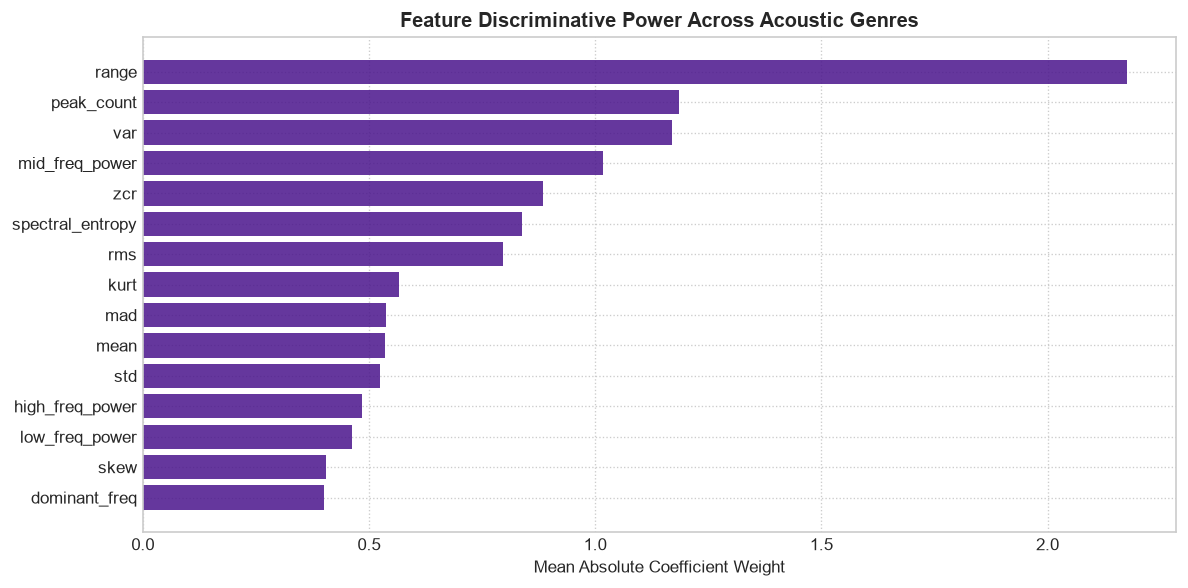

In [5]:
scaler = StandardScaler()
X_norm = scaler.fit_transform(X_music)

lr_model = LogisticRegression(max_iter=1000, penalty='l2', C=1.0)
lr_model.fit(X_norm, y_music)

coef_mean = np.mean(np.abs(lr_model.coef_), axis=0)
indices = np.argsort(coef_mean)[::-1]

plt.figure(figsize=(10, 5))
plt.barh(range(len(feature_cols)), coef_mean[indices][::-1], color="#4A148C", alpha=0.85)
plt.yticks(range(len(feature_cols)), [feature_cols[i] for i in indices][::-1])
plt.xlabel("Mean Absolute Coefficient Weight")
plt.title("Feature Discriminative Power Across Acoustic Genres", fontweight='bold')
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "3_feature_weights.png"), dpi=300, bbox_inches='tight')
plt.show()


## 6. Multi-Genre Radar Profile Chart

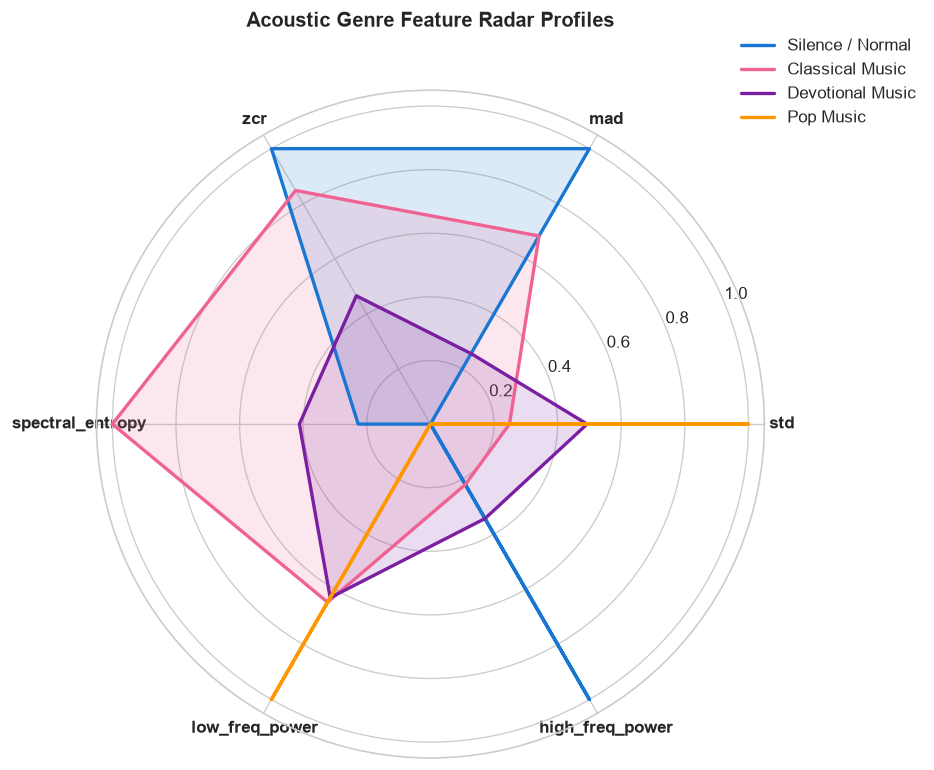

In [6]:
radar_features = ["std", "mad", "zcr", "spectral_entropy", "low_freq_power", "high_freq_power"]
radar_means = music_df.groupby("genre")[radar_features].mean()
radar_norm = (radar_means - radar_means.min()) / (radar_means.max() - radar_means.min() + 1e-9)

labels = radar_features
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
palette = {"Silence / Normal": "#1976D2", "Classical Music": "#F06292", "Devotional Music": "#7B1FA2", "Pop Music": "#FF9800"}

for genre in genres:
    values = radar_norm.loc[genre].tolist()
    values += values[:1]
    ax.plot(angles, values, label=genre, color=palette[genre], linewidth=2)
    ax.fill(angles, values, color=palette[genre], alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontweight='bold')
ax.set_title("Acoustic Genre Feature Radar Profiles", fontweight='bold', y=1.08)
plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1))
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "4_genre_radar_profiles.png"), dpi=300, bbox_inches='tight')
plt.show()
